# ДЗ-1. Рекомендации продуктов по отзывам Amazon
**Студент: Колесников Федор Дмитриевич**  
Amazon Reviews 2014 · Grocery and Gourmet Food · 5-core · seed = 2026.

Цель работы — сравнить пять самостоятельно реализованных методов персональных top-10 рекомендаций: ItemKNN с Jaccard, iALS, EASE, FM с историческими метапризнаками и iALS с целевым сигналом, учитывающим оценку и давность. Дополнительно проверяется FM только с ID.

Рекомендуются ещё не оценённые пользователем товары. Релевантность одинакова для всех моделей: **будущий отзыв с оценкой 4 или 5**. Основная метрика заранее выбрана — **NDCG@10**. Итоги и интерпретация вычисленных результатов приведены в разделе 7.

## 1. Как воспроизвести эксперимент
Python 3.12, CPU. Из корня проекта:
```bash
python -m venv .venv
source .venv/bin/activate  # Windows: .venv\Scripts\activate
python -m pip install -r requirements.txt
python -m unittest discover -s tests -v
python run_notebook.py
```
Архив (~35 МБ) скачивается автоматически в `data/`. Можно заранее поместить туда `reviews_Grocery_and_Gourmet_Food_5.json.gz` или задать `RECSYS_DATA_DIR`. Данные, окружение и кеши исключены из Git. Ноутбук сохранён с выполненными ячейками; повторный запуск заново обучает модели. Для матриц EASE желательно иметь не менее 8 ГБ свободной RAM. Все вычисления используют один поток; скорость зависит от процессора.

Зависимости закреплены в `requirements.txt`, полная среда — в `requirements-lock.txt`; проверенные версии также выводятся ниже. PyTorch используется для autograd и Adam, а не как готовая рекомендательная модель.

In [1]:
import os
os.environ['OMP_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
import json, random, platform, time, importlib.metadata
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_pipeline import (load_raw, clean_data, build_training, evaluation_cohort,
                           VALID_START, TEST_START, SOURCE_URL, DATA_URL, ORIGINAL_URL, DATA_SHA256)
from experiment import SEARCH, SEED, PRIMARY_METRIC, search_models, final_evaluation
from evaluation import paired_bootstrap
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)
thread_limits=threadpool_limits(limits=1)
RESULTS=Path('results'); RESULTS.mkdir(exist_ok=True)
BLUE, GOLD, ORANGE = '#285A8E', '#B18B2D', '#C36638'
plt.rcParams.update({'font.size':11, 'figure.dpi':120, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.18})
versions={p:importlib.metadata.version(p) for p in ['numpy','scipy','pandas','torch','matplotlib','nbformat','nbclient']}
(RESULTS/'environment.json').write_text(json.dumps({'python':platform.python_version(),
    'platform':platform.platform(), 'packages':versions,'seed':SEED,'threads':1},indent=2))
display(pd.Series(versions,name='Версия').to_frame())

,Версия
numpy,2.2.6
scipy,1.15.3
pandas,2.2.3
torch,2.6.0
matplotlib,3.10.1
nbformat,5.10.4
nbclient,0.10.2


## 2. Источник, постановка и очистка
[Первоисточник: Amazon product data, Julian McAuley / UCSD](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/links.html). Используется опубликованный **5-core Grocery and Gourmet Food**: 151 254 отзыва, а не полный набор Amazon. В 5-core у каждого пользователя и товара не менее пяти отзывов **за весь период**. Пользователь подтвердил, что этот набор не использовался на семинарах.

Старый сервер Stanford не отвечал при подготовке работы. Поэтому автоматическая загрузка использует [публичную копию архива, закреплённую за коммитом](https://github.com/ParsProgrammer/Exp-RS/blob/4cb769058e2e06801dcb991d7212432d88c09fc2/reviews_Grocery_and_Gourmet_Food_5.json.gz). Ссылка на оригинал и SHA-256 скачанной копии выводятся ниже. Размер, поля и число наблюдений сверены с описанием первоисточника; побайтовое совпадение с недоступным оригинальным сервером независимо не подтверждено.

| Поле | Назначение |
|---|---|
| reviewerID | ID пользователя |
| asin | ID товара |
| overall | Оценка 1–5; ≥4 — положительный интерес |
| unixReviewTime | Дата публикации, временное разбиение и давность |
| summary | Заголовок отзыва; текстовые признаки товара из прошлых отзывов |

Один отзыв — одно взаимодействие. Удаляются дубликаты выбранных полей, строки без ключевых полей и некорректные оценки/даты. Если пара user–item повторяется, сохраняется **первый** отзыв, чтобы будущая запись не заменяла прошлую. Отзывы 1–3 не объявляются положительными, но сохраняются для маски уже известных товаров и исторических метапризнаков. Пустой summary заменяется пустой строкой. Фильтр 5-core повторно не применяется.

**Ограничение выборки:** исходный 5-core сформирован с использованием активности за весь период. Поэтому это ретроспективный benchmark активной подвыборки, а не несмещённая симуляция всего Amazon. Внутри неё обучение, признаки и подбор используют только доступное прошлое.

In [2]:
print('Первоисточник:', SOURCE_URL)
print('Оригинальный файл:', ORIGINAL_URL)
print('Использованный mirror:', DATA_URL)
print('SHA-256:', DATA_SHA256)
raw=load_raw()
display(pd.DataFrame({'Пропуски':raw.isna().sum(), 'Доля':raw.isna().mean()}).round(4))
print('Дубликаты выбранных полей:',int(raw.duplicated().sum()))
events,cleaning=clean_data(raw)
display(cleaning)
cleaning.to_csv(RESULTS/'cleaning.csv',index=False)

Первоисточник: https://mcauleylab.ucsd.edu/public_datasets/data/amazon/links.html
Оригинальный файл: https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/reviews_Grocery_and_Gourmet_Food_5.json.gz
Использованный mirror: https://raw.githubusercontent.com/ParsProgrammer/Exp-RS/4cb769058e2e06801dcb991d7212432d88c09fc2/reviews_Grocery_and_Gourmet_Food_5.json.gz
SHA-256: 77c5b65fb395dcd24f6a81d95d2ea471e8d9a82b70431b39919c14ab52547dd1


,Пропуски,Доля
reviewerID,0,0.0
asin,0,0.0
overall,0,0.0
unixReviewTime,0,0.0
summary,0,0.0


Дубликаты выбранных полей: 0


,Этап,Строки
0,Исходные отзывы 5-core,151254
1,Без полных дубликатов выбранных полей,151254
2,"Валидные ID, время и оценка 1–5",151254
3,Первая оценка каждой пары пользователь–товар,151254


In [3]:
nu, ni=events.reviewerID.nunique(), events.asin.nunique()
positive=events[events.overall>=4]
summary={'reviews':len(events),'positive_reviews':len(positive),'users':nu,'items':ni,
         'observed_sparsity':1-len(events)/(nu*ni),'positive_sparsity':1-len(positive)/(nu*ni),
         'first_date':str(events.time.min()),'last_date':str(events.time.max()),
         'empty_summary_fraction':float(events.summary.str.strip().eq('').mean())}
display(pd.Series(summary).to_frame('Значение'))
assert 100_000<=len(events)<=2_000_000 and nu>=1000 and ni>=1000
assert len(positive)>=100_000
(RESULTS/'dataset_summary.json').write_text(json.dumps(summary,indent=2))

,Значение
reviews,151254
positive_reviews,120044
users,14681
items,8713
observed_sparsity,0.998818
positive_sparsity,0.999062
first_date,2000-08-09 00:00:00
last_date,2014-07-23 00:00:00
empty_summary_fraction,0.0


284

### Активность, популярность и оценки
Распределения относятся ко всем очищенным отзывам. Даже внутри 5-core активность неравномерна; логарифмические оси помогают увидеть длинный хвост. Оценки анализируются отдельно, поскольку отзыв сам по себе ещё не означает положительного отношения.

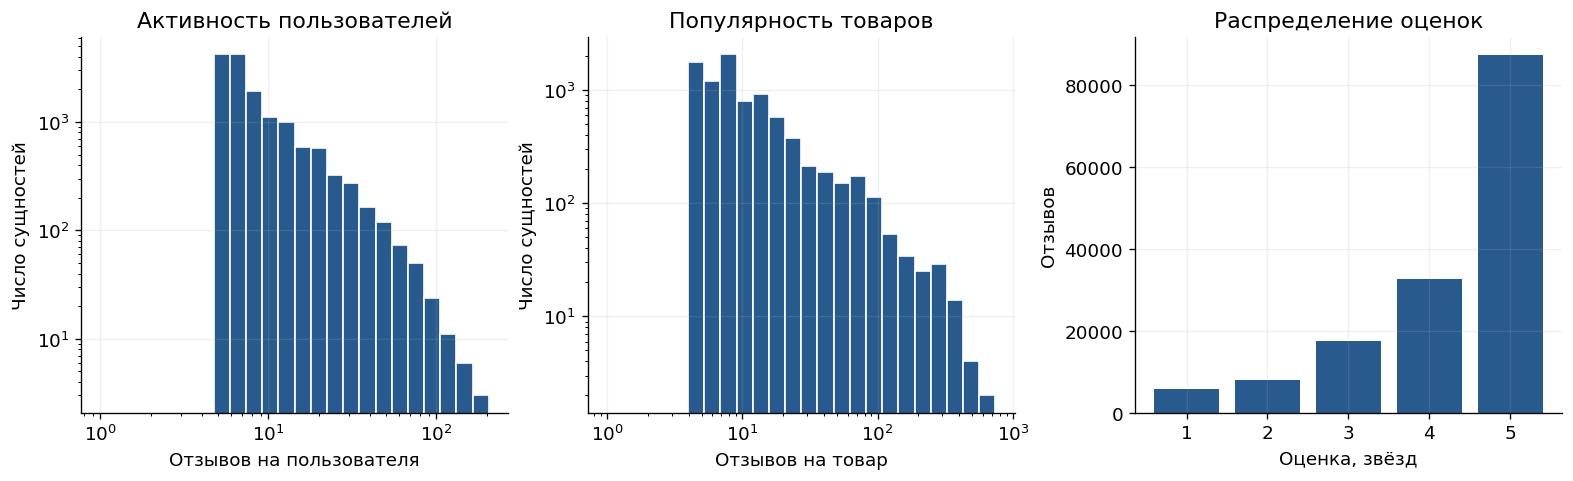

,Отзывов на пользователя,Отзывов на товар
count,14681.0,8713.0
mean,10.3,17.4
std,10.6,33.9
min,5.0,5.0
25%,5.0,6.0
50%,7.0,8.0
75%,11.0,14.0
max,204.0,742.0


Положительных отзывов: 79.4%.


In [4]:
activity=events.groupby('reviewerID').size(); popularity=events.groupby('asin').size()
fig,axes=plt.subplots(1,3,figsize=(13,3.9),layout='constrained')
for ax,values,title,xlabel in [(axes[0],activity,'Активность пользователей','Отзывов на пользователя'),
                              (axes[1],popularity,'Популярность товаров','Отзывов на товар')]:
    ax.hist(values,bins=np.geomspace(1,values.max()+1,25),color=BLUE,edgecolor='white')
    ax.set(xscale='log',yscale='log',title=title,xlabel=xlabel,ylabel='Число сущностей')
ratings=events.overall.value_counts().sort_index()
axes[2].bar(ratings.index,ratings.values,color=BLUE)
axes[2].set(title='Распределение оценок',xlabel='Оценка, звёзд',ylabel='Отзывов',xticks=[1,2,3,4,5])
fig.savefig(RESULTS/'eda_distributions.png',bbox_inches='tight'); plt.show()
display(pd.DataFrame({'Отзывов на пользователя':activity.describe(),
                      'Отзывов на товар':popularity.describe()}).round(1))
print(f'Положительных отзывов: {len(positive)/len(events):.1%}.')

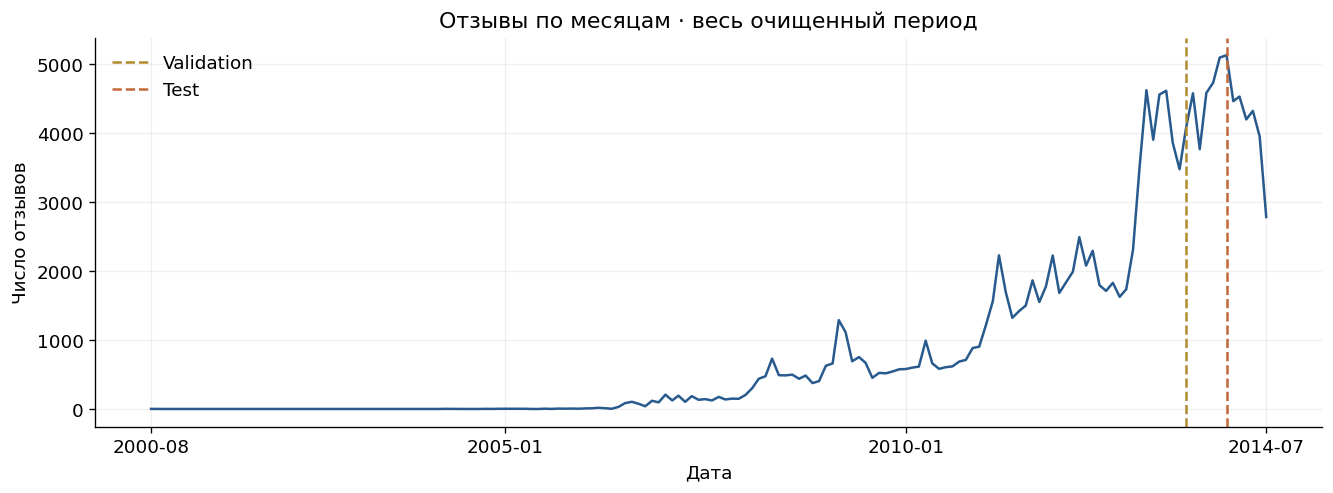

Последний месяц неполный; рост числа отзывов влияет на временную репрезентативность.


In [5]:
monthly=events.set_index('time').resample('MS').size()
fig,ax=plt.subplots(figsize=(11,4),layout='constrained')
ax.plot(monthly.index,monthly.values,color=BLUE)
for date,label,color in [(VALID_START,'Validation',GOLD),(TEST_START,'Test',ORANGE)]:
    ax.axvline(date,color=color,ls='--',label=label)
ax.set(title='Отзывы по месяцам · весь очищенный период',xlabel='Дата',ylabel='Число отзывов')
ax.set_xticks([monthly.index[0],pd.Timestamp('2005-01-01'),pd.Timestamp('2010-01-01'),monthly.index[-1]])
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')); ax.legend(frameon=False)
fig.savefig(RESULTS/'eda_time.png',bbox_inches='tight'); plt.show()
print('Последний месяц неполный; рост числа отзывов влияет на временную репрезентативность.')

## 3. Общий протокол и метапризнаки
Train: дата < **01.07.2013**. Validation: **01.07.2013 ≤ дата < 01.01.2014**. Test: **дата ≥ 01.01.2014**. Границы фиксируются до обучения; все отзывы одного дня попадают в один период. Unix timestamp переводится в UTC, затем используется календарная дата.

Каждая модель выбирается по NDCG@10 на validation. После фиксации настроек модели обучаются заново на train+validation и один раз оцениваются на test. Каталог и признаки заморожены на начало окна.

**Пользователи и кандидаты.** В обучение входят пользователи и товары с хотя бы одним положительным отзывом до границы. Оцениваются общие для всех моделей warm-start пользователи хотя бы с одним новым положительным отзывом на известный товар. Кандидаты — весь каталог, за исключением **всех** ранее оценённых пользователем товаров, включая оценки 1–3. Отрицательной подвыборки при оценке нет. Cold-start и пользователи без подходящей релевантности учитываются в аудите, но не входят в знаменатель метрик. Равные scores разрешаются по отсортированному ASIN.

**Метапризнаки FM.** Помимо user/item ID используются до шести слов из опубликованных до границы summary данного товара, а также категории его прошлой средней оценки, числа отзывов и возраста с первого отзыва. Словарь строится заново на каждом обучающем срезе: английские слова ≥3 букв, фиксированный список стоп-слов, document frequency от 5 до 30% каталога, не более 2 000 слов. Для товара выбираются шесть слов с максимальным TF-IDF; реализация находится в `data_pipeline.py`. Все ненулевые признаки — multi-hot.

Фиксированные границы корзин: средняя оценка `[2,3,3.5,4,4.5]`, число отзывов `[2,5,10,20,50,100]`, возраст в днях `[30,90,180,365,730,1460]`. Границы не оцениваются по test. Тексты будущих отзывов, будущие средние оценки, итоговые helpfulness, related-products граф и цены на дату сбора не используются. Snapshot-признаки одинаковы при обучении и оценке соответствующей модели; это модель рекомендаций на границе окна, а не предсказание каждого исторического отзыва в его собственный момент времени.

In [6]:
train_events=events[events.time<VALID_START].copy()
valid_events=events[(events.time>=VALID_START)&(events.time<TEST_START)].copy()
test_events=events[events.time>=TEST_START].copy()
split=pd.DataFrame([{'split':name,'reviews':len(x),'positive':int((x.overall>=4).sum()),
    'users':x.reviewerID.nunique(),'items':x.asin.nunique(), 'start':x.time.min(),'end':x.time.max()}
    for name,x in [('train',train_events),('validation',valid_events),('test',test_events)]])
display(split); split.to_csv(RESULTS/'split_summary.csv',index=False)
train=build_training(train_events,VALID_START)
valid_truth,valid_audit=evaluation_cohort(valid_events,train)
display(pd.Series(valid_audit).to_frame('Validation audit'))
print('Размер train-матрицы:',train.binary.shape,'; положительных пар:',train.binary.nnz)
print('Размер словаря:',len(train.vocabulary))
print('Товаров без выбранных текстовых слов:',int((train.features[:,1:7].sum(axis=1)==0).sum()))

,split,reviews,positive,users,items,start,end
0,train,95007,73826,12602,8107,2000-08-09,2013-06-30
1,validation,26850,21764,8118,6114,2013-07-01,2013-12-31
2,test,29397,24454,8379,6163,2014-01-01,2014-07-23


,Validation audit
future_reviews,26850
future_positive_pairs,21764
cold_user_pairs,5329
cold_item_pairs,3873
warm_pairs,12959
already_seen_pairs,0
novel_relevant_pairs,12959
evaluated_users,5322
future_users,8118
catalog_items,8012


Размер train-матрицы: (12322, 8012) ; положительных пар: 73826
Размер словаря: 2000
Товаров без выбранных текстовых слов: 52


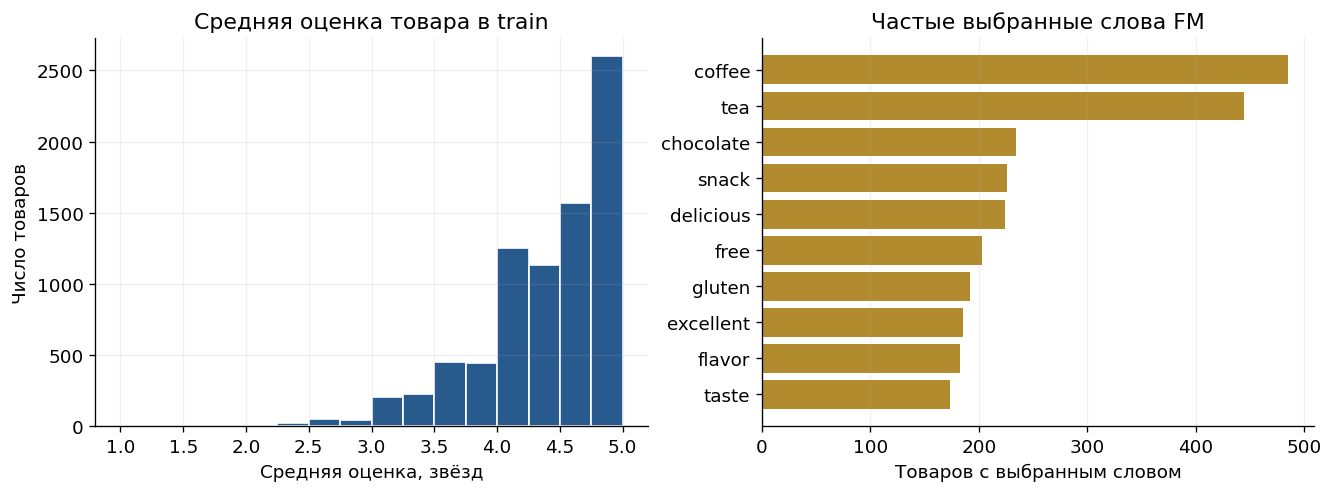

In [7]:
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].hist(train.metadata.mean_rating,bins=np.linspace(1,5,17),color=BLUE,edgecolor='white')
axes[0].set(title='Средняя оценка товара в train',xlabel='Средняя оценка, звёзд',ylabel='Число товаров')
reverse_vocab={v:w for w,v in train.vocabulary.items()}
frequencies=Counter(int(x) for x in train.features[:,1:7].ravel() if x)
common=frequencies.most_common(10)[::-1]
axes[1].barh([reverse_vocab[x] for x,n in common],[n for x,n in common],color=GOLD)
axes[1].set(title='Частые выбранные слова FM',xlabel='Товаров с выбранным словом')
axes[1].grid(axis='y',visible=False)
fig.savefig(RESULTS/'eda_metadata.png',bbox_inches='tight'); plt.show()

## 4. Модели и метрики
Пусть $R_{ui}=1$ для известной оценки 4–5, иначе $0$. $S_u$ — все ранее оценённые товары, независимо от оценки. Во всех методах вычисляется score полного каталога, позиции $S_u$ маскируются, выбираются десять максимальных значений.

### 4.1. ItemKNN: Jaccard
Для множеств положительных пользователей товара $U_i$:
$$s_{ij}=\frac{|U_i\cap U_j|}{|U_i\cup U_j|}\frac{|U_i\cap U_j|}{|U_i\cap U_j|+\beta},\quad s_{ii}=0.$$
В каждом столбце оставляются $k$ соседей. Прогноз: $\hat r_u=R_uS$. Jaccard сравнивает долю общих пользователей в объединении; shrinkage снижает вес совпадений на малом числе отзывов.

### 4.2. iALS
$$\min_{X,Y}\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2),$$
где $p=R$, $c_{ui}=1+\alpha\log(2)$ для положительной пары и $c=1$ иначе. Повторных пар после очистки нет. Обновление пользователя:
$$x_u=(Y^TY+\sum_{i:R_{ui}=1}(c_{ui}-1)y_iy_i^T+\lambda I)^{-1}\sum_{i:R_{ui}=1}c_{ui}p_{ui}y_i.$$
Обновление товаров симметрично; используются линейные solve, а не явное обращение этих малых матриц. Оценки 1–3 входят в нулевой фон и маску уже известных объектов.

### 4.3. EASE
$$\min_B\|R-RB\|_F^2+\lambda\|B\|_F^2,\quad \mathrm{diag}(B)=0.$$
Для $P=(R^TR+\lambda I)^{-1}$ решение $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, $B_{ii}=0$. Score $R_uB$. Вычисления плотные по товарам, поэтому метод требует $O(I^2)$ памяти.

### 4.4. FM
$$f(z)=w_0+\sum_jw_jz_j+\frac12\sum_f\left[(\sum_jv_{jf}z_j)^2-\sum_jv_{jf}^2z_j^2\right].$$
$z$ включает user ID, item ID и описанные выше исторические метапризнаки товара. Обучение: binary cross-entropy с logits, Adam и weight decay. На положительную пару берутся три равномерно выбранных **неизвестных до границы** товара; проверка исключает любые уже оценённые товары. Непросмотренный товар — шумный отрицательный пример, а не доказанная неприязнь. Информация о будущих отзывах не используется при sampling: будущая положительная пара может попасть в шумные отрицательные примеры. При оценке применяется точное разложение FM для быстрого scoring полного каталога.

### 4.5. iALS с рейтингом и давностью в target
Для положительной оценки $r_{ui}\in\{4,5\}$ и возраста $a_{ui}>0$ в днях:
$$p^{custom}_{ui}=\frac{r_{ui}-3}{2}\left(\frac12+\frac12e^{-a_{ui}/\tau}\right),$$
для остальных пар $p=0$. Пять звёзд дают более сильный сигнал, чем четыре; давность плавно ослабляет интерес, но оставляет половину его силы. Это гипотеза о полезности силы предпочтения и свежести. Меняется **сам target**, а не только confidence. Rank, $\lambda$, $\alpha$, число итераций и seed берутся из выбранного базового iALS; подбирается лишь $\tau$. Снижение масштаба target может менять эффективную регуляризацию, поэтому эффект нельзя приписать одной лишь давности.

### Метрики при K=10
$$Recall@10(u)=\frac{|Top10(u)\cap G_u|}{|G_u|},$$
$$NDCG@10(u)=\frac{\sum_{j=1}^{10}\mathbb{1}[i_j\in G_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|G_u|)}1/\log_2(j+1)}.$$
$G_u$ — множество новых известных товаров с будущей оценкой ≥4. NDCG учитывает позицию релевантного товара, Recall — полноту найденных предпочтений. Обе метрики усредняются по одинаковым пользователям, каждый имеет вес 1. Дополнительно $Coverage@10$ — доля всего известного каталога, попавшая хотя бы в одну рекомендацию; это охват, а не точность. Метрики реализованы самостоятельно в `evaluation.py`.

## 5. Настройка на validation
Пространство поиска определено в `experiment.py` до запуска. Всего 16 конфигураций: 4 ItemKNN, 4 iALS, 3 EASE, 2 FM и 3 Custom iALS. Выбор — максимум NDCG@10, при равенстве первая конфигурация в фиксированном порядке. Для абляции FM ID-only сохраняются выбранные настройки FM и число эпох. Бюджет компактный; это не исчерпывающая оптимизация каждого метода.

In [8]:
for name,configs in SEARCH.items():
    display(Markdown('**'+name+'**')); display(pd.DataFrame(configs))
display(Markdown('**Custom iALS:** выбранный iALS + tau_days ∈ {365,730,1460}. **FM IDs only:** выбранный FM, metadata=False.'))

**ItemKNN**

,k,shrink
0,30,10
1,30,30
2,80,10
3,80,30


**iALS**

,factors,reg,alpha,iterations,seed
0,24,5.0,10.0,8,2026
1,24,20.0,10.0,8,2026
2,48,5.0,10.0,8,2026
3,48,20.0,10.0,8,2026


**EASE**

,reg
0,20.0
1,100.0
2,400.0


**FM**

,factors,lr,weight_decay,epochs,negatives,batch_size,metadata,seed
0,24,0.005,0.00001,5,3,4096,True,2026
1,24,0.005,0.00001,10,3,4096,True,2026


**Custom iALS:** выбранный iALS + tau_days ∈ {365,730,1460}. **FM IDs only:** выбранный FM, metadata=False.

In [9]:
started=time.perf_counter()
validation,selected=search_models(train,valid_truth,RESULTS)
display(validation[['model','NDCG@10','Recall@10','Coverage@10','fit_seconds']].round(5))
display(pd.DataFrame([{'model':n,**p} for n,p in selected.items()]).set_index('model').T.fillna('—'))
print('Параметры зафиксированы в selected_params.json. Переходим к финальному test.')

ItemKNN: NDCG@10=0.02122, Recall@10=0.02988


ItemKNN: NDCG@10=0.02191, Recall@10=0.03060


ItemKNN: NDCG@10=0.02149, Recall@10=0.03003


ItemKNN: NDCG@10=0.02197, Recall@10=0.03050


iALS: NDCG@10=0.02046, Recall@10=0.03070


...

Custom iALS: NDCG@10=0.02500, Recall@10=0.03691


Custom iALS: NDCG@10=0.02469, Recall@10=0.03593


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds
0,ItemKNN,0.02122,0.02988,0.87681,2.00748
1,ItemKNN,0.02191,0.03060,0.87332,1.72272
2,ItemKNN,0.02149,0.03003,0.86845,1.58341
3,ItemKNN,0.02197,0.03050,0.86345,2.41604
4,iALS,0.02046,0.03070,0.05017,3.90850
5,iALS,0.01989,0.03069,0.04468,3.61620
6,iALS,0.02321,0.03406,0.07751,5.85918
7,iALS,0.02338,0.03432,0.06852,5.74747
8,EASE,0.02383,0.03248,0.77222,4.59350
9,EASE,0.02525,0.03567,0.72678,5.38078


model,ItemKNN,iALS,EASE,FM,Custom iALS,FM IDs only
k,80.0,—,—,—,—,—
shrink,30.0,—,—,—,—,—
factors,—,48.0,—,24.0,48.0,24.0
reg,—,20.0,100.0,—,20.0,—
alpha,—,10.0,—,—,10.0,—
iterations,—,8.0,—,—,8.0,—
seed,—,2026.0,—,2026.0,2026.0,2026.0
lr,—,—,—,0.005,—,0.005
weight_decay,—,—,—,0.00001,—,0.00001
epochs,—,—,—,10.0,—,10.0


Параметры зафиксированы в selected_params.json. Переходим к финальному test.


## 6. Финальная оценка
Модели с зафиксированными параметрами заново обучаются на всей истории до 01.01.2014. Test не участвует в подборе, словаре, статистике метапризнаков или early stopping. Таблица аудита показывает исключённые cold-start пары; группы cold user и cold item могут пересекаться, поэтому их нельзя просто складывать.

Время первого обучения FM включает инициализацию PyTorch/Adam; показанные секунды не являются чистым сравнением вычислительной стоимости методов.

In [10]:
final_train=build_training(events[events.time<TEST_START],TEST_START)
test_truth,test_audit=evaluation_cohort(test_events,final_train)
display(pd.DataFrame([valid_audit,test_audit],index=['validation','test']).T)
(RESULTS/'cohort_audit.json').write_text(json.dumps({'validation':valid_audit,'test':test_audit},indent=2,default=int))
results,per_user,examples=final_evaluation(final_train,test_truth,selected,RESULTS)
print(f'Поиск и финальная оценка: {(time.perf_counter()-started)/60:.1f} минут.')
display(results[['model','NDCG@10','Recall@10','Coverage@10','fit_seconds','eval_seconds']].round(5))

,validation,test
future_reviews,26850,29397
future_positive_pairs,21764,24454
cold_user_pairs,5329,4994
cold_item_pairs,3873,3209
warm_pairs,12959,16387
already_seen_pairs,0,0
novel_relevant_pairs,12959,16387
evaluated_users,5322,6192
future_users,8118,8379
catalog_items,8012,8527


Test ItemKNN: NDCG@10=0.02108, Recall@10=0.02962


Test iALS: NDCG@10=0.02305, Recall@10=0.03389


Test EASE: NDCG@10=0.02596, Recall@10=0.03623


Test FM: NDCG@10=0.01251, Recall@10=0.02040


Test Custom iALS: NDCG@10=0.02718, Recall@10=0.03988


Test FM IDs only: NDCG@10=0.01964, Recall@10=0.03200


Поиск и финальная оценка: 4.2 минут.


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds,eval_seconds
0,Custom iALS,0.02718,0.03988,0.07283,6.50056,2.75634
1,EASE,0.02596,0.03623,0.69919,6.16982,13.88112
2,iALS,0.02305,0.03389,0.07341,6.39972,2.75712
3,ItemKNN,0.02108,0.02962,0.86431,2.37840,0.72640
4,FM IDs only,0.01964,0.03200,0.01876,1.90208,2.80335
5,FM,0.01251,0.02040,0.05770,5.05255,2.71186


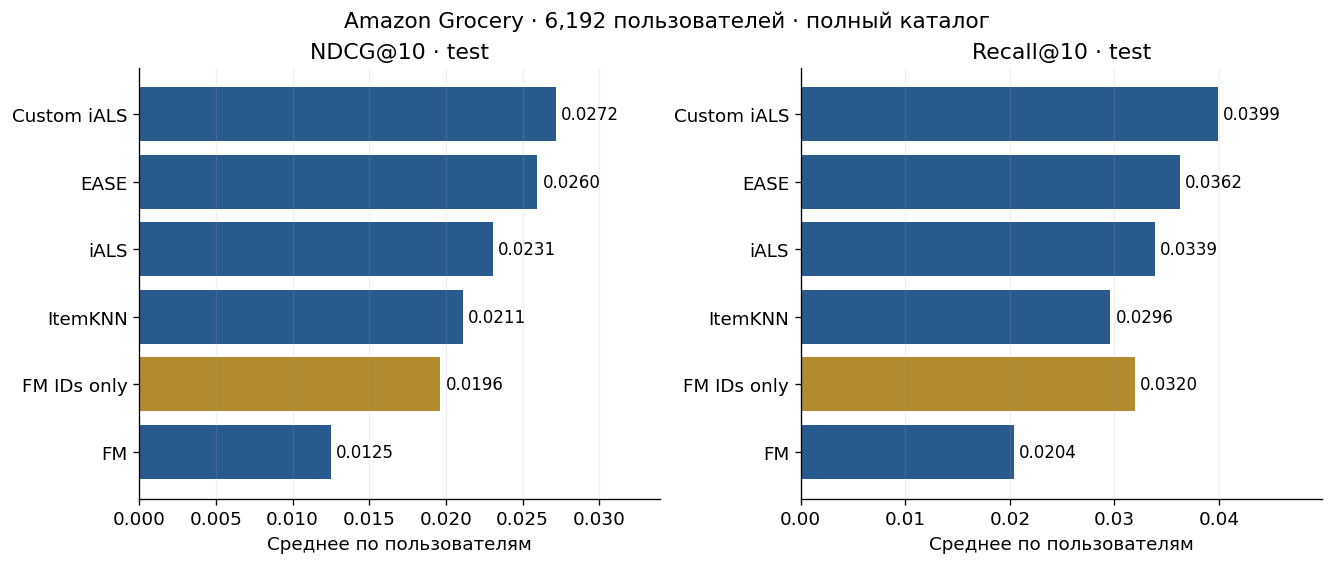

In [11]:
ordered=results.iloc[::-1]
fig,axes=plt.subplots(1,2,figsize=(11,4.6),layout='constrained')
for ax,metric in zip(axes,['NDCG@10','Recall@10']):
    bars=ax.barh(ordered.model,ordered[metric],color=[GOLD if x=='FM IDs only' else BLUE for x in ordered.model])
    ax.bar_label(bars,fmt='%.4f',padding=3,fontsize=10)
    ax.set(xlim=(0,ordered[metric].max()*1.25),title=metric+' · test',xlabel='Среднее по пользователям')
    ax.grid(axis='y',visible=False)
fig.suptitle(f'Amazon Grocery · {len(test_truth):,} пользователей · полный каталог',fontsize=13)
fig.savefig(RESULTS/'model_comparison.png',bbox_inches='tight'); plt.show()

### Контролируемые сравнения
Парный bootstrap по пользователям, 2 000 повторов, seed=2026. Для каждой выборки считаем разность средних NDCG@10; показываем 95% percentile-интервалы. Это неопределённость состава текущей test-когорты, а не устойчивость по времени или seed модели и не причинный эффект. Абляция FM сравнивает признаки при одинаковых настройках, а не два независимо оптимизированных метода.

,comparison,mean_delta,ci_low,ci_high
0,Custom iALS − iALS,0.004133,0.002599,0.005706
1,FM metadata − FM IDs only,-0.007130,-0.009269,-0.005151


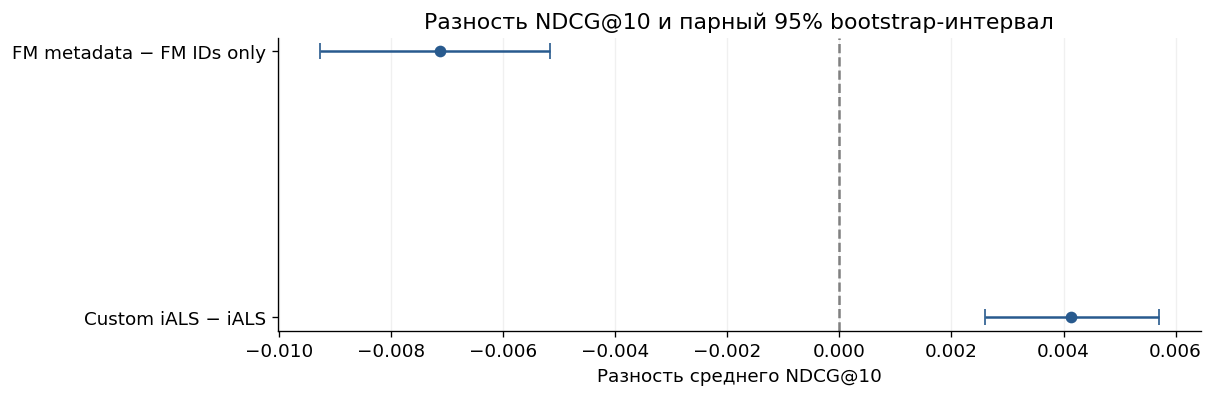

In [12]:
contrasts=pd.DataFrame([{'comparison':label,**paired_bootstrap(per_user[a]['NDCG@10'],per_user[b]['NDCG@10'],seed=SEED)}
    for a,b,label in [('Custom iALS','iALS','Custom iALS − iALS'),('FM','FM IDs only','FM metadata − FM IDs only')]])
display(contrasts.round(6)); contrasts.to_csv(RESULTS/'paired_bootstrap.csv',index=False)
fig,ax=plt.subplots(figsize=(10,3.2),layout='constrained')
y=np.arange(len(contrasts)); d=contrasts.mean_delta.to_numpy()
ax.errorbar(d,y,xerr=np.vstack([d-contrasts.ci_low,contrasts.ci_high-d]),fmt='o',color=BLUE,capsize=5)
ax.axvline(0,color='gray',ls='--'); ax.set_yticks(y,contrasts.comparison)
ax.set(title='Разность NDCG@10 и парный 95% bootstrap-интервал',xlabel='Разность среднего NDCG@10')
ax.grid(axis='y',visible=False)
fig.savefig(RESULTS/'ablation_intervals.png',bbox_inches='tight'); plt.show()

### Пример рекомендации
Первый пользователь test-когорты по внутреннему индексу, фиксированное правило без отбора удачных примеров. Показывается победитель среди пяти основных моделей; настоящие reviewerID не публикуются. ASIN — публичный идентификатор товара. В примере отмечается именно будущая положительная оценка, а не любой отзыв.

In [13]:
main_results=results[results.model!='FM IDs only']
winner=main_results.iloc[0]['model']; user=sorted(test_truth)[0]; recommended=examples[winner][0]
example=pd.DataFrame({'rank':np.arange(1,11),'ASIN':final_train.items[recommended],
    'средняя оценка до test':final_train.metadata.iloc[recommended].mean_rating.to_numpy().round(2),
    'положительный отзыв на test':np.isin(recommended,test_truth[user])})
assert not set(recommended)&set(final_train.seen[user].indices)
display(example); example.to_csv(RESULTS/'example_recommendations.csv',index=False)

,rank,ASIN,средняя оценка до test,положительный отзыв на test
0,1,B004391DK0,4.33,False
1,2,B0034EDLS2,4.67,False
2,3,B000VK4DXO,4.38,False
3,4,B000CQE3HS,4.19,False
4,5,B001D05RWC,4.58,False
5,6,B000ENUC3S,4.48,False
6,7,B000CQ01NS,4.23,False
7,8,B002TXT502,4.90,False
8,9,B00DILCU92,3.84,False
9,10,B0010YA02S,4.42,False


## 7. Выводы по выполненному эксперименту
Числа и формулировки ниже вычисляются из результатов. При повторном запуске выводы обновятся вместе с таблицами.

In [14]:
best=main_results.iloc[0]; second=main_results.iloc[1]
custom=contrasts.iloc[0]; meta=contrasts.iloc[1]
def effect(row):
    if row.ci_low>0: return 'прирост; интервал не включает ноль'
    if row.ci_high<0: return 'ухудшение; интервал не включает ноль'
    return 'интервал включает ноль, уверенного различия на этой когорте не обнаружено'
conclusion=f"""
1. **Лучшая из пяти основных моделей — {best['model']}**: NDCG@10 = **{best['NDCG@10']:.5f}**, Recall@10 = **{best['Recall@10']:.5f}**. Следующая — {second['model']} с NDCG@10 = {second['NDCG@10']:.5f}. Настройки победителя: `{selected[best['model']]}`. Это результат данного временного окна и ограниченного поиска.
2. **Target с оценкой и давностью:** Custom iALS − iALS = **{custom.mean_delta:+.5f}** NDCG@10, 95% CI [{custom.ci_low:+.5f}; {custom.ci_high:+.5f}]: {effect(custom)}. Confidence и остальные параметры совпадают. Изменение масштаба target также влияет на баланс с регуляризацией.
3. **Исторические метапризнаки FM:** FM − FM IDs only = **{meta.mean_delta:+.5f}**, 95% CI [{meta.ci_low:+.5f}; {meta.ci_high:+.5f}]: {effect(meta)}. Вывод относится к этой схеме признаков и фиксированному режиму обучения; ID-only отдельно не оптимизировался.
4. Test охватывает **{test_audit['evaluated_users']:,}** из **{test_audit['future_users']:,}** пользователей будущего окна. Релевантных пар — **{test_audit['novel_relevant_pairs']:,}**, кандидатов в общем каталоге — **{test_audit['catalog_items']:,}** до персонального исключения известных товаров. Результат условен на warm start и наличие положительного будущего отзыва.
"""
display(Markdown(conclusion)); _ = (RESULTS/'conclusions.txt').write_text(conclusion,encoding='utf-8')


1. **Лучшая из пяти основных моделей — Custom iALS**: NDCG@10 = **0.02718**, Recall@10 = **0.03988**. Следующая — EASE с NDCG@10 = 0.02596. Настройки победителя: `{'factors': 48, 'reg': 20.0, 'alpha': 10.0, 'iterations': 8, 'seed': 2026, 'tau_days': 365.0}`. Это результат данного временного окна и ограниченного поиска.
2. **Target с оценкой и давностью:** Custom iALS − iALS = **+0.00413** NDCG@10, 95% CI [+0.00260; +0.00571]: прирост; интервал не включает ноль. Confidence и остальные параметры совпадают. Изменение масштаба target также влияет на баланс с регуляризацией.
3. **Исторические метапризнаки FM:** FM − FM IDs only = **-0.00713**, 95% CI [-0.00927; -0.00515]: ухудшение; интервал не включает ноль. Вывод относится к этой схеме признаков и фиксированному режиму обучения; ID-only отдельно не оптимизировался.
4. Test охватывает **6,192** из **8,379** пользователей будущего окна. Релевантных пар — **16,387**, кандидатов в общем каталоге — **8,527** до персонального исключения известных товаров. Результат условен на warm start и наличие положительного будущего отзыва.


### Ограничения и возможные улучшения
- Отзывы — выбранные пользователями события, а не логи показов или покупок. Неизвестные товары могут нравиться пользователю; ranking-метрики не доказывают рост продаж. Оценки 1–3 не трактуются как положительный сигнал.
- 5-core отобран по всему периоду: эксперимент смещён к активным пользователям и популярным товарам. Cold start, новые товары и пользователи без подходящих положительных отзывов не оцениваются.
- Используется один временной split и один seed. Для устойчивости нужны несколько rolling-origin окон и seed с новым holdout, без дальнейшей настройки на текущем test.
- Статистика товара и тексты прошлых summary являются историческими прокси метаданных. Источник не содержит историю редактирования отзывов, поэтому неизменность текста после даты публикации проверить нельзя. Наличие товара в продаже также неизвестно.
- Подбор ограничен; влияние добавления признаков не означает, что любая FM с метаданными будет лучше. Усреднение и bins могут скрывать неоднородность оценок; TF-IDF summary не использует полноценное понимание текста.
- Общий код линейной алгебры и FM адаптирован из [предыдущего проекта](https://github.com/NikkiVeid/recsys-hw1-online-retail); для этого набора изменены подготовка данных, Jaccard-сходство, метапризнаки, целевой сигнал, протокол и все результаты. Готовые реализации рекомендательных моделей не используются.

### Источники
- McAuley et al. (2015), *Image-based Recommendations on Styles and Substitutes*, SIGIR. [Страница датасета и библиография](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/links.html).
- Hu, Koren, Volinsky (2008), [Collaborative Filtering for Implicit Feedback Datasets](https://yifanhu.net/PUB/cf.pdf).
- Steck (2019), [Embarrassingly Shallow Autoencoders for Sparse Data](https://arxiv.org/abs/1905.03375).
- Rendle (2010), [Factorization Machines](https://doi.org/10.1109/ICDM.2010.127).

Обучение, score, top-K и метрики реализованы в коде проекта. NumPy/SciPy используются для линейной алгебры; PyTorch — для автоматического дифференцирования FM. Проверки формул и протокола находятся в `tests/`.